# Was he recognised? The PFA Team of the Year model, and the all-time table

**The model** is the one from the Yaya Touré report, extended to ten seasons (2010/11 to 2019/20): a logistic
regression that predicts PFA Team of the Year selection from six per-90 numbers (as percentiles within each season)
plus minutes. Each season is predicted by a model trained on the other nine. Expected selections = the sum of a
player's predicted chances; compare with actual selections.

**The all-time table** compares Premier League career totals per appearance for the great midfielders, with Hall of
Fame status (Eden Hazard, inducted in 2025, added from his Premier League record: 245 games, 85 goals, 54 assists).

Charts 7 to 9 of the report.

In [1]:
import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib import font_manager

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()  # project folder
EXT = ROOT / "data" / "external"
DARK_THEME = os.environ.get("REPORT_THEME") == "dark"  # dark = black-background charts for the PDF; the README uses the light ones
FIGS = ROOT / "reports" / ("figures_dark" if DARK_THEME else "figures")
FIGS.mkdir(parents=True, exist_ok=True)

SKY, NAVY, GREY, DARK, MUTED, LIGHT, GOLD = "#6CABDD", "#1C2C5B", "#B4B2A9", "#2B2B2A", "#6B6A64", "#F4F2EE", "#C9A227"
BG, GRID, SPAN, HEAT, HEAT_HI = "white", "#ECEAE4", "#FBF3DC", [NAVY, SKY, "#E8F1FA", "#FFFFFF"], "white"
if DARK_THEME:  # on black, the emphasis colour (navy) becomes sky blue and the secondary blue gets deeper
    SKY, NAVY, GREY, DARK, MUTED = "#2F6FA6", "#6CABDD", "#4A4A50", "#ECECEC", "#9A9AA0"
    BG, GRID, SPAN, HEAT, HEAT_HI = "#000000", "#222226", "#2A2410", ["#8CC3EC", "#3D7DB3", "#17283A", "#0B0B0D"], "#000000"
SRC_PL = "Data: Premier League official stats (Opta), premierleague.com. Midfielders as listed in each club's squad, 2010/11 to 2019/20"
for _f in (ROOT / "assets" / "fonts").glob("*.ttf"):  # Barlow, bundled with the project (SIL Open Font License)
    font_manager.fontManager.addfont(str(_f))
plt.rcParams.update({
    "font.family": "Barlow", "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight", "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": GREY,
    "axes.labelcolor": DARK, "xtick.color": DARK, "ytick.color": DARK,
    "figure.facecolor": BG, "axes.facecolor": BG, "savefig.facecolor": BG, "text.color": DARK, "legend.labelcolor": DARK,
})


def fs(light, pdf):
    """Figure size: the README (light) size, or a narrower one for the PDF so the text prints larger on the page."""
    return pdf if DARK_THEME else light


def titles(fig, title, subtitle, source, y=1.06):
    fig.suptitle(title, x=0.01, y=y, ha="left", va="bottom", fontsize=17, fontweight="bold", color=DARK, family="Barlow Condensed")
    fig.text(0.01, y - 0.005, subtitle, ha="left", va="top", fontsize=10.5, color=MUTED)
    fig.text(0.01, -0.03, source, ha="left", va="top", fontsize=8, color=MUTED)


def season_label(s):
    """2011 -> '2011/12'"""
    return f"{s}/{str(s + 1)[-2:]}"


def load_opta(min_minutes=0):
    """Every Premier League midfielder, 2010/11 to 2019/20 (official Opta stats). Season = starting year."""
    d = pd.concat([pd.read_csv(EXT / "pl_midfielders_2010-2018.csv"), pd.read_csv(EXT / "pl_midfielders_2018-2020.csv")])
    d = d.drop_duplicates(["season", "id"])
    d = d[d.timePlayed >= min_minutes].copy()
    p90 = lambda s: s / d.timePlayed * 90
    d["npg"] = d.goals - d.penaltyGoals
    d["scoring"] = p90(d.npg)                                   # non-penalty goals per 90
    d["assisting"] = p90(d.goalAssists)                         # assists per 90
    d["creating"] = p90(d.keyPassesAttemptAssists)              # chances created per 90
    d["passing"] = p90(d.successfulPassesOppositionHalf)        # completed passes in the opposition half per 90
    d["carrying"] = p90(d.successfulDribbles)                   # successful dribbles per 90
    d["defending"] = p90(d.tacklesWon + d.interceptions)        # tackles won + interceptions per 90
    d["through"] = p90(d.throughBalls)                          # through balls per 90
    d["box"] = p90(d.totalTouchesInOppositionBox)               # touches in the opposition box per 90
    d["dribbles"] = d.successfulDribbles + d.unsuccessfulDribbles
    d["dribble_pct"] = d.successfulDribbles / d.dribbles.where(d.dribbles > 0)
    return d


DIMS = ["scoring", "assisting", "creating", "passing", "carrying", "defending"]
DIM_LABELS = {"scoring": "Scoring\n(non-penalty goals)", "assisting": "Assisting\n(assists)", "creating": "Creating\n(chances created)",
              "passing": "Passing\n(passes in opp. half)", "carrying": "Carrying\n(successful dribbles)",
              "defending": "Defending\n(tackles won + interceptions)"}
SILVA = "David Silva"
TITLES = {2011: "Champions", 2013: "Champions", 2017: "Champions", 2018: "Champions"}

In [2]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import GroupKFold, cross_val_predict

M = load_opta(min_minutes=1800)
for c in DIMS:
    M["p_" + c] = M.groupby("season")[c].rank(pct=True)
M["p_minutes"] = M.groupby("season").timePlayed.rank(pct=True)
T = pd.read_csv(EXT / "pfa_team_of_the_year.csv")
T["start"] = T.season.str[:4].astype(int)
picked = set(zip(T.start, T.player))
M["toty"] = [(s, n) in picked for s, n in zip(M.season, M.name)]
FEATS = ["p_" + c for c in DIMS] + ["p_minutes"]
M["prob"] = cross_val_predict(LogisticRegression(max_iter=2000), M[FEATS], M.toty, groups=M.season, cv=GroupKFold(10), method="predict_proba")[:, 1]
model = LogisticRegression(max_iter=2000).fit(M[FEATS], M.toty)
COEF = pd.Series(model.coef_[0], index=FEATS)
print(f"{len(M)} seasons, {M.toty.sum()} selections; held-out AUC {roc_auc_score(M.toty, M.prob):.2f}")
COEF.round(2)

757 seasons, 36 selections; held-out AUC 0.87


p_scoring      1.67
p_assisting    1.41
p_creating     0.10
p_passing      1.99
p_carrying     1.71
p_defending    0.24
p_minutes      2.02
dtype: float64

In [3]:
CAREER = M.groupby("name").agg(seasons=("season", "size"), expected=("prob", "sum"), actual=("toty", "sum"))
CAREER["gap"] = CAREER.actual - CAREER.expected
print(CAREER.loc[SILVA].round(2).to_dict())
CAREER[CAREER.seasons >= 3].sort_values("gap").head(6).round(2)

{'seasons': 10.0, 'expected': 1.81, 'actual': 3.0, 'gap': 1.19}


,seasons,expected,actual,gap
name,,,,
Mesut Özil,5,0.96,0,-0.96
Santiago Cazorla,3,0.94,0,-0.94
Ross Barkley,4,0.55,0,-0.55
Cesc Fàbregas,4,0.42,0,-0.42
Aaron Ramsey,5,0.41,0,-0.41
Gylfi Sigurdsson,6,0.38,0,-0.38


In [4]:
M[M.name == SILVA][["season", "prob", "toty"] + FEATS].round(2)

,season,prob,toty,p_scoring,p_assisting,p_creating,p_passing,p_carrying,p_defending,p_minutes
117,2010,0.13,False,0.62,0.85,0.91,0.89,0.73,0.18,0.59
303,2011,0.29,True,0.80,1.00,0.99,0.96,0.75,0.19,0.76
489,2012,0.16,False,0.70,0.94,1.00,0.94,0.73,0.20,0.50
677,2013,0.14,False,0.93,0.97,1.00,1.00,0.63,0.12,0.25
874,2014,0.30,False,0.98,0.84,0.99,0.96,0.75,0.19,0.70
1061,2015,0.06,False,0.57,0.99,0.95,0.97,0.65,0.25,0.01
1269,2016,0.16,False,0.59,0.82,0.95,0.97,0.72,0.20,0.66
1464,2017,0.25,True,0.96,0.97,0.89,1.00,0.68,0.16,0.59
109,2018,0.22,False,0.88,0.97,0.97,0.99,0.69,0.21,0.53
278,2019,0.10,True,0.97,0.99,0.90,0.97,0.82,0.13,0.03


In [5]:
G = pd.read_csv(EXT / "pl_career_midfield_greats.csv")
G["a_pg"] = G.assists / G.appearances
G["ga_pg"] = (G.goals + G.assists) / G.appearances
G.sort_values("a_pg", ascending=False).round(2)

,name,player_id,appearances,goals,assists,pl_titles,hall_of_fame,a_pg,ga_pg
7,Kevin De Bruyne,61366,288,72,119,6,no,0.41,0.66
6,Cesc Fàbregas,17878,350,50,111,2,no,0.32,0.46
5,David Silva,20664,309,60,93,4,no,0.30,0.50
10,Eden Hazard,0,245,85,54,2,2025,0.22,0.57
1,Steven Gerrard,1814,504,120,92,0,2021,0.18,0.42
2,Frank Lampard,2051,609,177,102,3,2021,0.17,0.46
0,Yaya Touré,14664,230,62,32,3,no,0.14,0.41
4,Patrick Vieira,1593,307,31,34,3,2022,0.11,0.21
3,Paul Scholes,363,499,107,55,11,2022,0.11,0.32
9,Michael Carrick,2404,481,24,40,5,no,0.08,0.13


## Charts

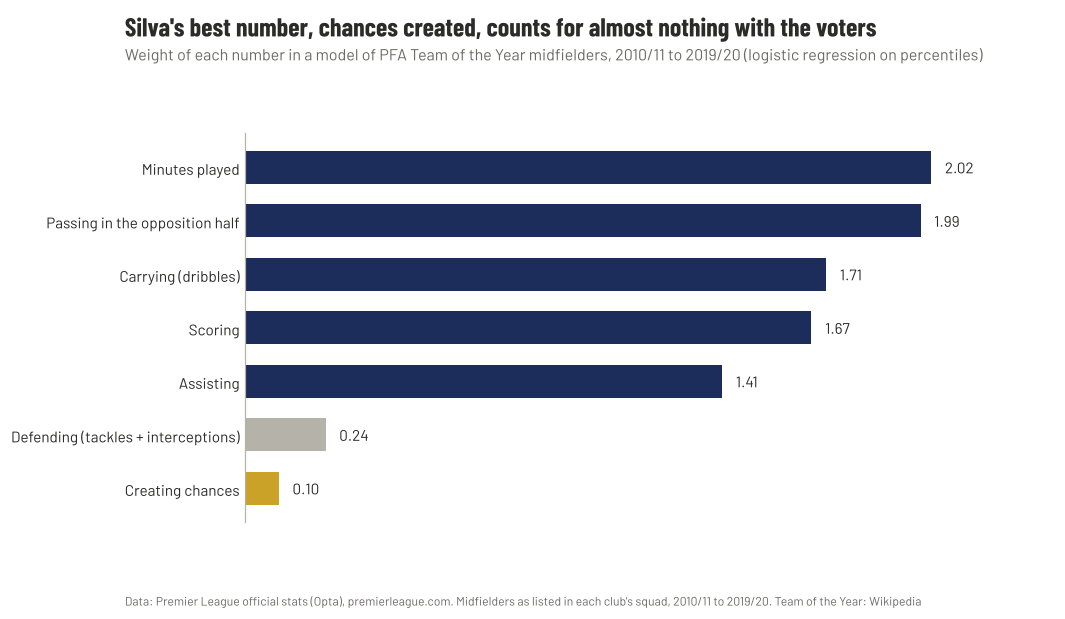

In [6]:
# Figure 7: what the voters reward, with creating highlighted
lab = {"p_scoring": "Scoring", "p_assisting": "Assisting", "p_creating": "Creating chances", "p_passing": "Passing in the opposition half",
       "p_carrying": "Carrying (dribbles)", "p_defending": "Defending (tackles + interceptions)", "p_minutes": "Minutes played"}
c = COEF.sort_values()
fig, ax = plt.subplots(figsize=(9.5, 4.6))
ax.barh(range(len(c)), c.values, color=[GOLD if k == "p_creating" else NAVY if v >= 1 else GREY for k, v in c.items()], height=0.62)
for i, v in enumerate(c.values):
    ax.text(max(v, 0) + 0.04, i, f"{v:.2f}", va="center", fontsize=10, color=DARK)
ax.set_yticks(range(len(c)), [lab[k] for k in c.index], fontsize=10)
ax.set_xticks([]); ax.spines["bottom"].set_visible(False); ax.tick_params(axis="y", length=0); ax.set_xlim(0, c.max() * 1.18)
titles(fig, "Silva's best number, chances created, counts for almost nothing with the voters",
       "Weight of each number in a model of PFA Team of the Year midfielders, 2010/11 to 2019/20 (logistic regression on percentiles)",
       SRC_PL + ". Team of the Year: Wikipedia")
fig.savefig(FIGS / "07_what_voters_reward.png")

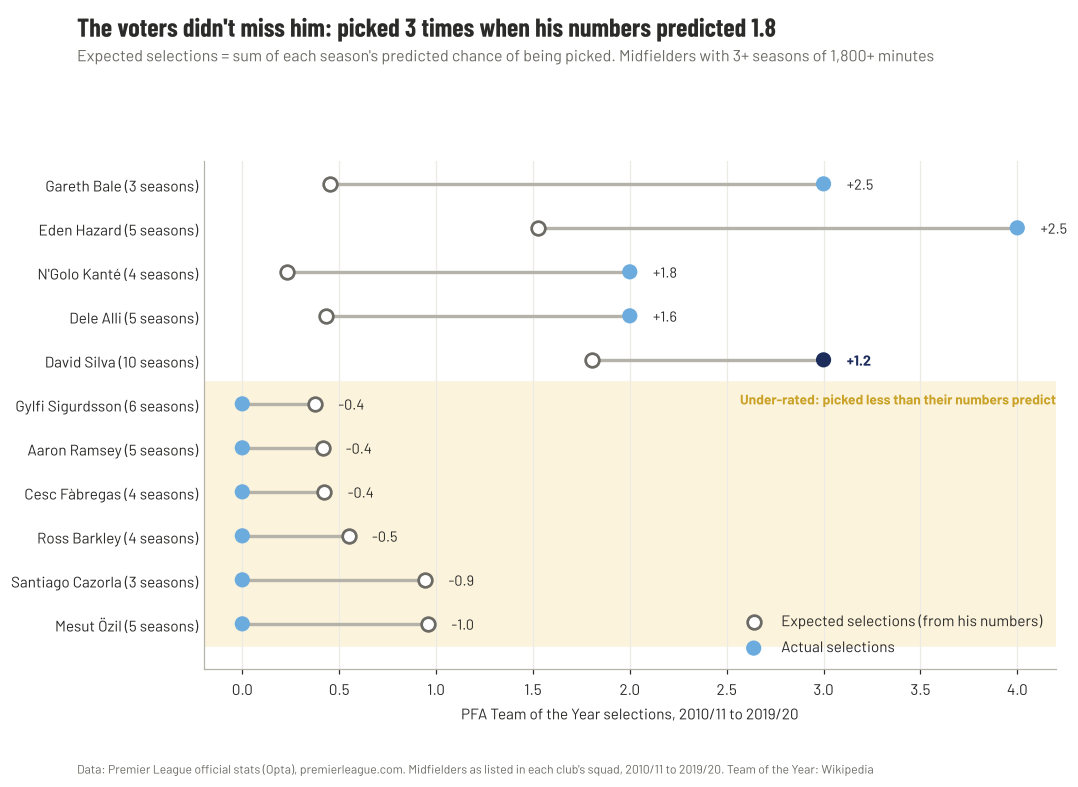

In [7]:
# Figure 8: expected vs actual selections
sub = CAREER[CAREER.seasons >= 3]
show = pd.concat([sub.sort_values("gap").head(6), sub.sort_values("gap", ascending=False).head(5)]).drop_duplicates()
if SILVA not in show.index:
    show = pd.concat([show, sub.loc[[SILVA]]])
show = show.sort_values("gap")
fig, ax = plt.subplots(figsize=fs((10, 6), (9, 5.8)))
yy = np.arange(len(show))
for yi, (n, r) in zip(yy, show.iterrows()):
    ax.plot([r.expected, r.actual], [yi, yi], color=GREY, lw=2.2, zorder=1)
ax.scatter(show.expected, yy, s=80, color=BG, edgecolors=MUTED, lw=1.8, zorder=2, label="Expected selections (from his numbers)")
ax.scatter(show.actual, yy, s=80, color=[NAVY if n == SILVA else SKY for n in show.index], zorder=3, label="Actual selections")
for yi, (n, r) in zip(yy, show.iterrows()):
    ax.text(max(r.expected, r.actual) + 0.12, yi, f"{r.gap:+.1f}", va="center", fontsize=9.5,
            color=NAVY if n == SILVA else DARK, fontweight="bold" if n == SILVA else "normal")
ax.set_yticks(yy, [f"{n} ({int(r.seasons)} seasons)" for n, r in show.iterrows()], fontsize=10)
ax.set_xlabel("PFA Team of the Year selections, 2010/11 to 2019/20"); ax.grid(axis="x", color=GRID); ax.set_axisbelow(True)
ax.tick_params(axis="y", length=0); ax.legend(frameon=False, loc="lower right")
ax.axhspan(-0.5, (show.gap < 0).sum() - 0.5, color=SPAN, zorder=0)
ax.text(ax.get_xlim()[1], (show.gap < 0).sum() - 0.7, "Under-rated: picked less than their numbers predict", ha="right", va="top", fontsize=9, color=GOLD, fontweight="bold")
r = CAREER.loc[SILVA]
titles(fig, f"The voters didn't miss him: picked {int(r.actual)} times when his numbers predicted {r.expected:.1f}",
       "Expected selections = sum of each season's predicted chance of being picked. Midfielders with 3+ seasons of 1,800+ minutes",
       SRC_PL + ". Team of the Year: Wikipedia")
fig.savefig(FIGS / "08_expected_vs_actual_selections.png")

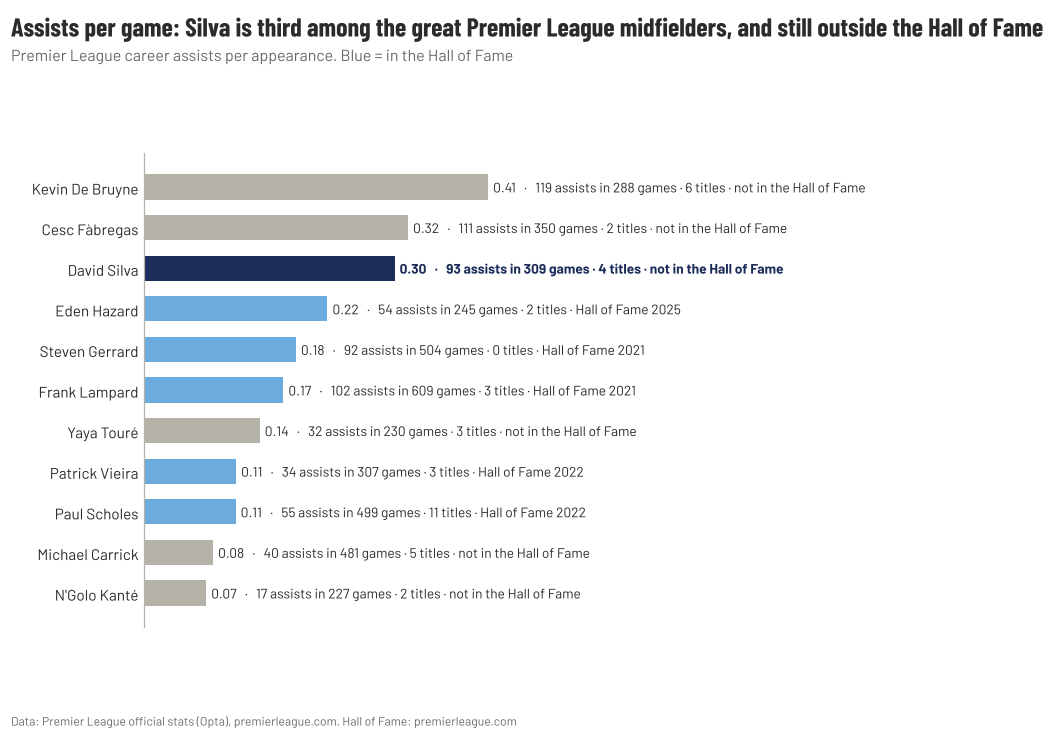

In [8]:
# Figure 9: against the all-time greats, per game
g = G.sort_values("a_pg")
fig, ax = plt.subplots(figsize=fs((10.5, 5.6), (9.6, 5.4)))
y = np.arange(len(g))
ax.barh(y, g.a_pg, color=[NAVY if n == SILVA else SKY if h != "no" else GREY for n, h in zip(g.name, g.hall_of_fame)], height=0.62)
for yi, r in zip(y, g.itertuples()):
    hof = f"Hall of Fame {r.hall_of_fame}" if r.hall_of_fame != "no" else "not in the Hall of Fame"
    ax.text(r.a_pg + 0.006, yi, f"{r.a_pg:.2f}   ·   {r.assists} assists in {r.appearances} games · {r.pl_titles} titles · {hof}", va="center", fontsize=9,
            color=NAVY if r.name == SILVA else DARK, fontweight="bold" if r.name == SILVA else "normal")
ax.set_yticks(y, g.name, fontsize=10); ax.set_xticks([]); ax.spines["bottom"].set_visible(False); ax.tick_params(axis="y", length=0)
ax.set_xlim(0, g.a_pg.max() * 2.6)
titles(fig, "Assists per game: Silva is third among the great Premier League midfielders, and still outside the Hall of Fame",
       "Premier League career assists per appearance. Blue = in the Hall of Fame", SRC_PL.split(". Mid")[0] + ". Hall of Fame: premierleague.com")
fig.savefig(FIGS / "09_all_time_assists_per_game.png")